# Phosphorylation rates in droplets

1. (De)phosphorylation rate of every serine by CK1δ and calcineurin (PP3), active vs passive droplets
2. Fraction of time each serine is phosphorylated
3. Number of pSer in time in droplets with only one kind of enzyme

Every analysis is saved in `analysis/friction01/droplet_200-tdp43-lcd/phosphorylation/` and reloaded (computed only if
its file is missing; `RECOMPUTE = True` in the setup cell redoes them). The fitted rates are written to `fitted_rates.txt`.

# Setup

In [19]:
import os
import sys

module_path = os.path.abspath('src')    # run the notebooks from the repository folder
if module_path not in sys.path:
    sys.path.insert(0, module_path)
from hpa.paths import SIM, AN, PL, INPUT_STATS, REPO, STYLES   # data locations (set HPA_DATA_ROOT to use another copy)

import numpy as np
from matplotlib import pyplot as plt
from scipy.optimize import curve_fit
import gsd.hoomd

import hpa.cluster as hpacl
import hpa.rates as hpar
from hpa.stats import linear

plt.style.use('default')
plt.style.use(STYLES + 'rates_plot.mplstyle')

In [23]:
path_drop_fr = SIM + 'droplet_200-tdp43-lcd/'
path_drop_fr_pl = PL + 'droplet_200-tdp43-lcd/'
rates_dir = AN + 'phosphorylation/'   # saved analyses
os.makedirs(rates_dir, exist_ok=True)
RECOMPUTE = False    # True: recompute every saved analysis

N_CHAINS = 200
CHAIN_LENGTH = 154
DT_SNAP = 200000    # MD steps between dump frames

# serines of the TDP-43 LCD (residue 261 = bead 0)
SER_I = np.array([266, 273, 292, 305, 317, 332, 333, 342, 347, 350, 369, 373, 375, 377, 379, 387, 389, 393, 395,
                  403, 404, 407, 409, 410]) - 260 - 1
SER_LABELS = SER_I + 1 + 260
X_SER = np.arange(1, len(SER_I) + 1)


def cached(filename, compute):
    '''Arrays saved in filename (.npz); computed with compute() -> {name: array} and saved if missing or RECOMPUTE.'''
    if RECOMPUTE or not os.path.exists(filename):
        np.savez(filename, **compute())
    with np.load(filename) as z:
        return {k: z[k] for k in z.files}


def savefig(prefix, dpi=600):
    for ext in ('png', 'pdf'):
        plt.savefig(f'{prefix}.{ext}', dpi=dpi)

# 1. Rates per serine (200 LCD chains, 2 CK1δ, 24 PP3)
Accepted reactions per serine, per µs and per enzyme; mean and standard error over 3 replicas.
Active: 10–30 ×10⁸ steps; passive (Δμ = 0): 20–30 ×10⁸ steps. Enzyme ids: 0–1 CK1δ, 2–25 PP3.

With `REMOVE_BACK_REACTIONS = True` the immediate back-reactions are not counted: a reaction reversed by the same enzyme
on the same bead one reaction step (200 MD steps) later. They are about 3% of the accepted reactions in the active
droplets but about half in the passive ones, so the passive rates depend on this choice (the A/B timelines of
`droplet_msm_rates.ipynb` count every accepted reaction).

In [3]:
REMOVE_BACK_REACTIONS = True     # False: count every accepted reaction
ENZYMES = {'k': [0, 1], 'p': list(range(2, 26))}
RUNS = {'active': ('ness', 10e8, 30e8), 'passive': ('dmu0', 20e8, 30e8)}
REACTIONS = {'phospho': 1, 'dephospho': -1}


def rate_per_ser(sim_type, start, end, reaction, enzymes):
    '''Rate of the reaction (+1 / -1) at every serine, per us and per enzyme.'''
    folder = f'sim_{sim_type}_200-tdp43-lcd_2-ck1d-open_24-pp3_fr01/'
    suffix = f'{sim_type}_200-tdp43-lcd_2-com-ck1d-open_24-com-pp3_CAL3_fr01_20us_contacts.txt'
    r, dr = hpar.count_contacts(dirpath=path_drop_fr + folder, file_suffix=suffix, ser_l=SER_I, n_sims=3,
                                type_of_contact=reaction, len_prot=CHAIN_LENGTH, n_prot=N_CHAINS, nenz=enzymes,
                                start=start, end=end, remove_back_reactions=REMOVE_BACK_REACTIONS)
    norm = (end - start) / 1e8 * len(enzymes)    # us * number of enzymes
    return r / norm, dr / norm


def compute_rates():
    out = {}
    for run, (sim_type, start, end) in RUNS.items():
        for reaction, sign in REACTIONS.items():
            for enz in ENZYMES:
                out[f'{run}_{reaction}_{enz}'], out[f'{run}_{reaction}_{enz}_err'] = rate_per_ser(sim_type, start, end, sign, ENZYMES[enz])
        # fraction of the accepted reactions in the window that are immediate back-reactions (replica 1)
        f = (path_drop_fr + f'sim_{sim_type}_200-tdp43-lcd_2-ck1d-open_24-pp3_fr01/'
             f'sim1_{sim_type}_200-tdp43-lcd_2-com-ck1d-open_24-com-pp3_CAL3_fr01_20us_contacts.txt')
        d = np.loadtxt(f)
        window = (d[:, 0] > start) & (d[:, 0] < end) & np.isin(d[:, 2], (1, -1))
        out[f'{run}_back_fraction'] = np.mean(hpar.back_reaction_mask(d)[window])
    return out


tag = '' if REMOVE_BACK_REACTIONS else '_with-back-reactions'
saved = cached(rates_dir + f'rates_per_ser_200-tdp43-lcd_2-ck1d-open_24-pp3{tag}.npz', compute_rates)
rates = {(run, reaction, enz): (saved[f'{run}_{reaction}_{enz}'], saved[f'{run}_{reaction}_{enz}_err'])
         for run in RUNS for reaction in REACTIONS for enz in ENZYMES}
for run in RUNS:
    print(f'{run}: {100 * saved[f"{run}_back_fraction"]:.1f}% of the accepted reactions are immediate back-reactions'
          f' ({"not counted" if REMOVE_BACK_REACTIONS else "counted"})')

for reaction in REACTIONS:
    print(reaction, 'total rate per enzyme:',
          {f'{run} {enz}': round(rates[run, reaction, enz][0].sum(), 4) for run in RUNS for enz in ENZYMES})

active: 3.1% of the accepted reactions are immediate back-reactions (not counted)
passive: 48.7% of the accepted reactions are immediate back-reactions (not counted)
phospho total rate per enzyme: {'active k': 104.35, 'active p': 0.3812, 'passive k': 3.7, 'passive p': 12.7611}
dephospho total rate per enzyme: {'active k': 0.0, 'active p': 9.2111, 'passive k': 3.4333, 'passive p': 12.8056}


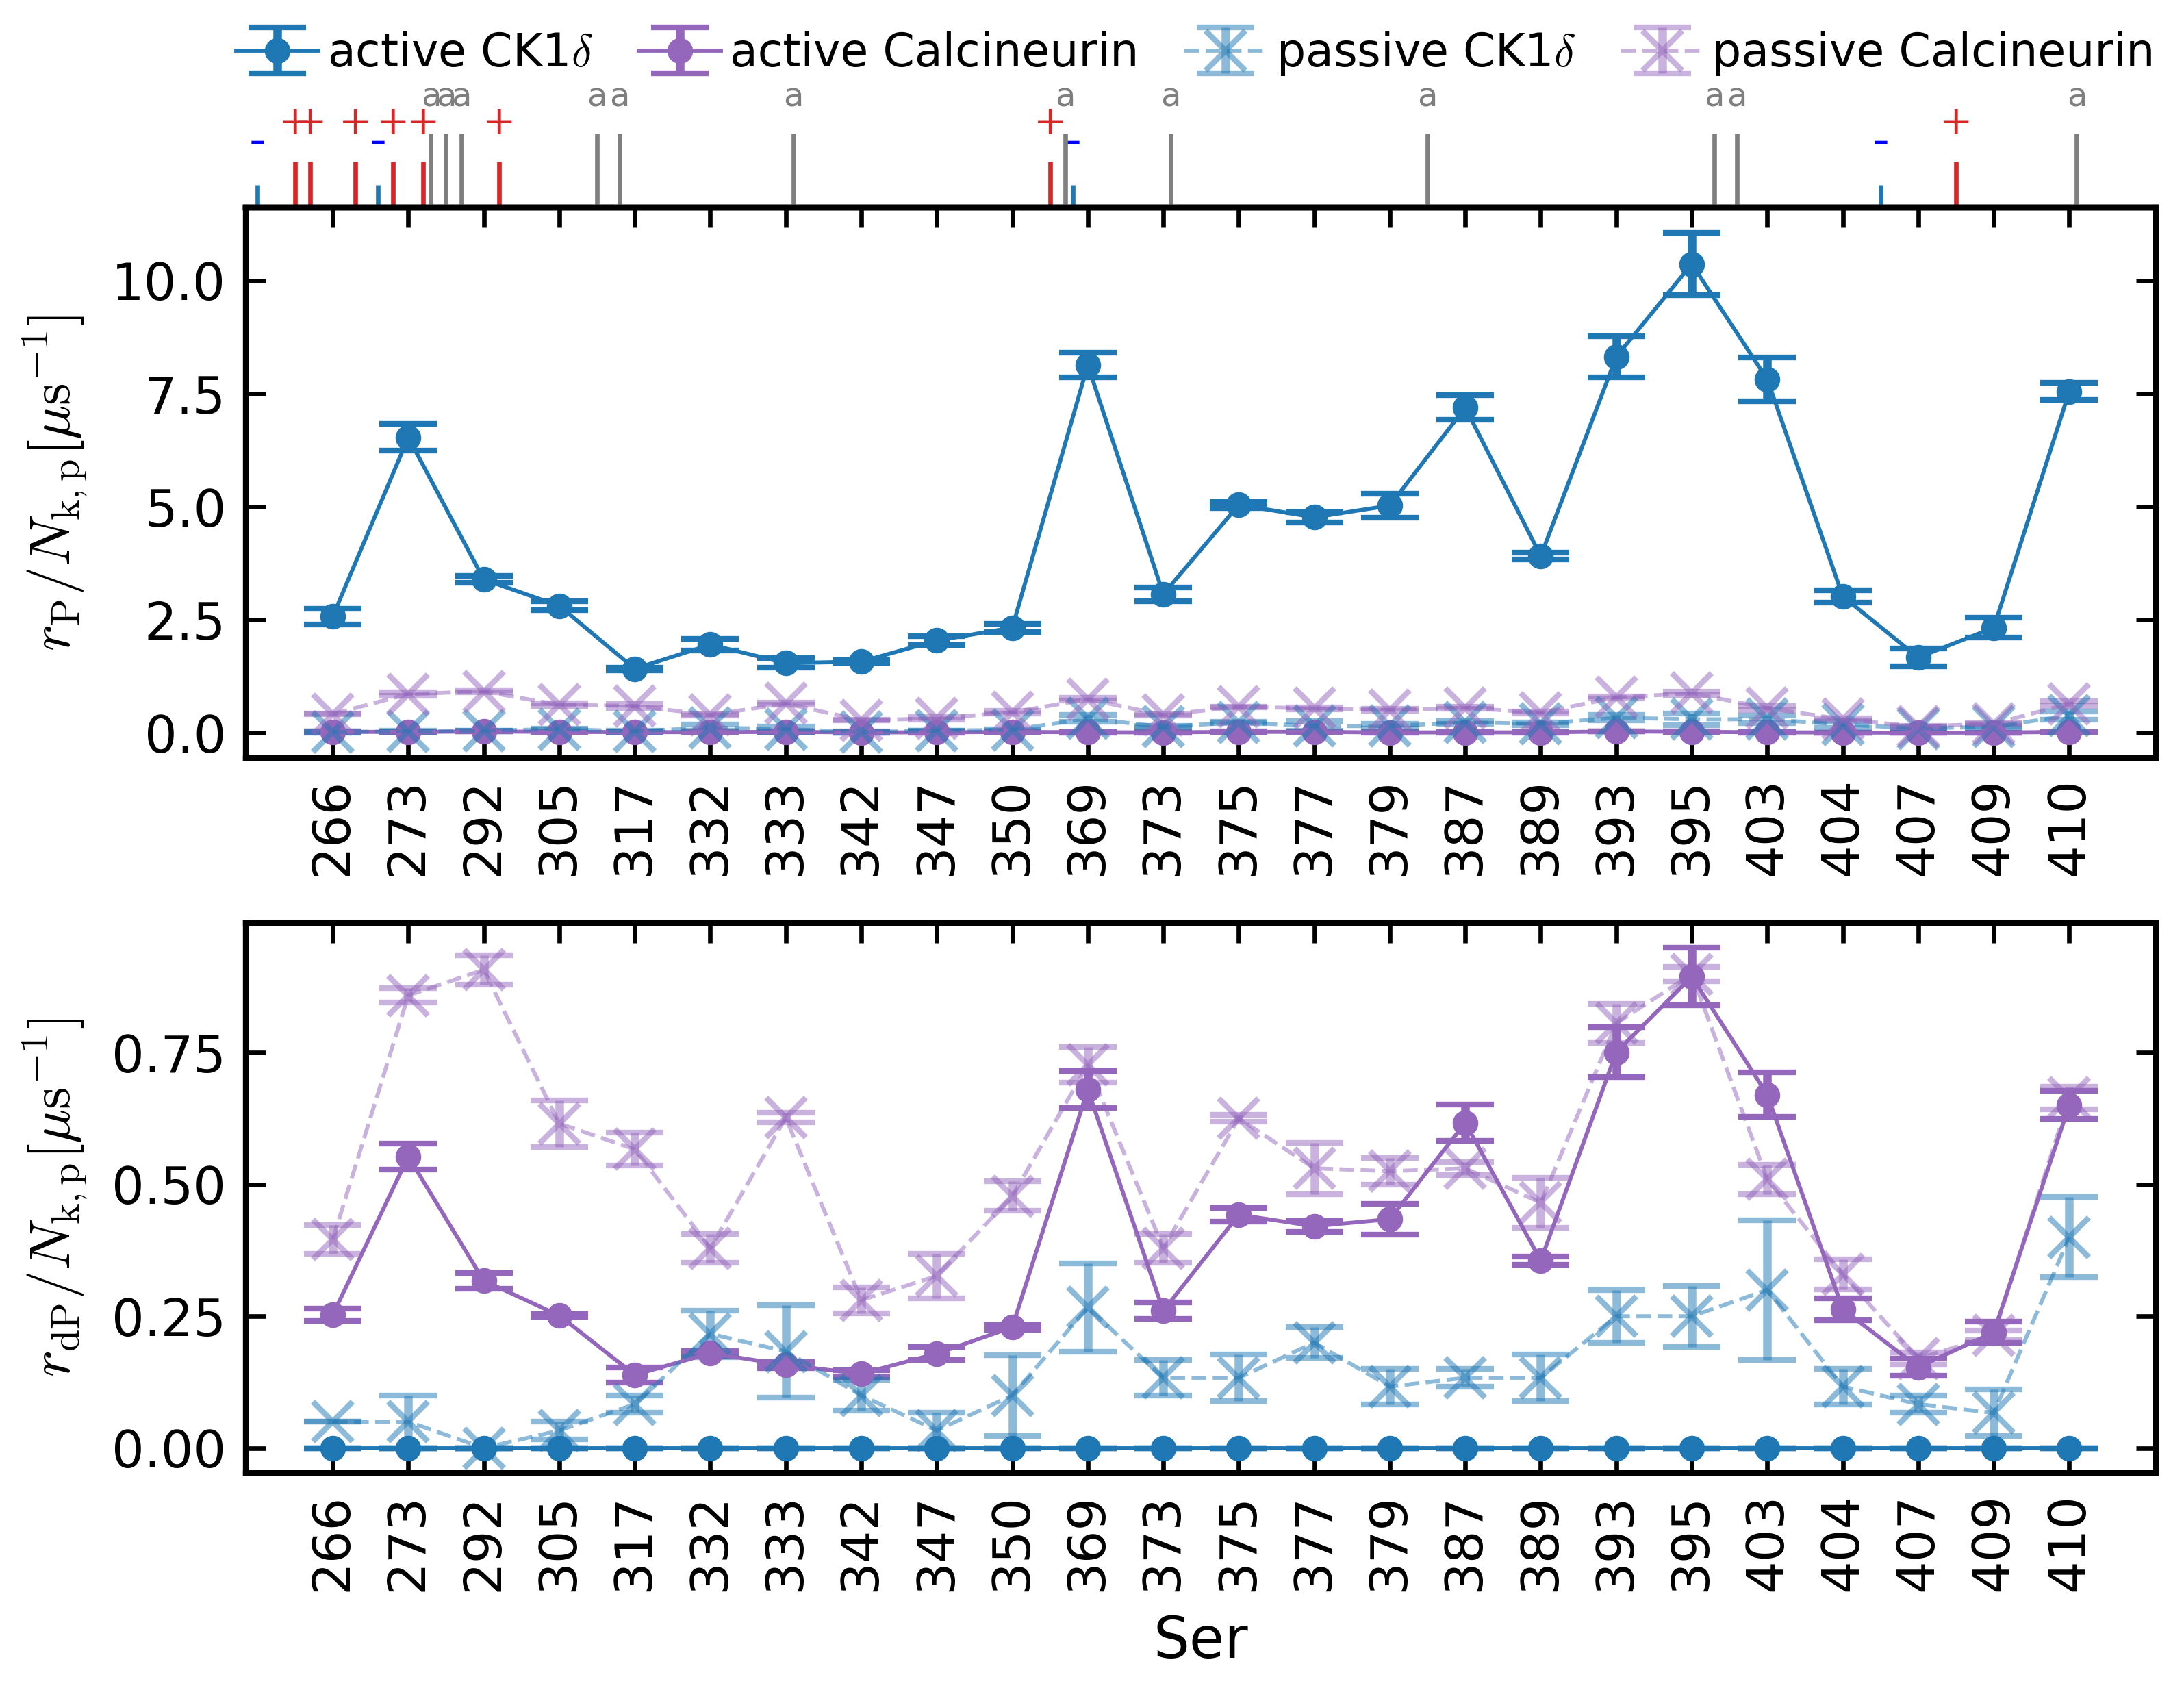

In [4]:
def annotate_charges(ax):
    '''Marks on the top axis: positive (+) and negative (-) charges, aromatic residues (a).'''
    for ticks, label, color, size, length in [
            ([0.5, 0.7, 1.3, 1.8, 2.2, 3.2, 10.5, 22.5], '+', 'tab:red', 'x-small', 8),
            ([0., 1.6, 10.8, 21.5], '-', 'blue', 'small', 4),
            ([2.3, 2.5, 2.7, 4.5, 4.8, 7.1, 10.7, 12.1, 15.5, 19.3, 19.6, 24.1], 'a', 'tab:grey', 'xx-small', 13)]:
        secax = ax.secondary_xaxis('top')
        secax.set_xticks(ticks, [label] * len(ticks), color=color, fontsize=size)
        secax.tick_params(direction='out', color='tab:blue' if label == '-' else color, length=length)


ENZ_STYLE = {'k': ('tab:blue', r'CK1$\delta$'), 'p': ('tab:purple', 'Calcineurin')}
RUN_STYLE = {'active': ('.-', 1.0), 'passive': ('x--', 0.5)}

f, axes = plt.subplots(2, 1, figsize=(6, 4.))
plt.subplots_adjust(hspace=0.3)
for ax, reaction in zip(axes, REACTIONS):
    for run, (fmt, alpha) in RUN_STYLE.items():
        for enz, (color, name) in ENZ_STYLE.items():
            r, dr = rates[run, reaction, enz]
            ax.errorbar(X_SER, r, dr, fmt=fmt, alpha=alpha, color=color, elinewidth=1.5, linewidth=.7, capsize=5,
                        markersize=7, label=f'{run} {name}')
    ax.set_xticks(X_SER, SER_LABELS, rotation='vertical')

annotate_charges(axes[0])
axes[0].legend(loc=(-0.01, 1.22), framealpha=0, ncols=4)
axes[1].set_xlabel('Ser')
axes[0].set_ylabel(r'$r_{\mathrm{P}}/N_{\mathrm{k,p}} [\mathrm{\mu s}^{-1}]$')
axes[1].set_ylabel(r'$r_{\mathrm{dP}}/N_{\mathrm{k,p}} [\mathrm{\mu s}^{-1}]$')
savefig(path_drop_fr_pl + f'phospho_dephospho_rates_active_vs_passive{tag}')

# 2. Fraction of time each serine is phosphorylated
From the reaction files, mean over the 200 chains (error bars: standard error over the chains of one replica).
- replica 1 of the droplet with 2 CK1δ and 10 PP3, in three windows: 0–8, 8–16, 16–26 ×10⁸ steps
- the three replicas of the droplet with 2 CK1δ and 16 PP3, 10–19.9 ×10⁸ steps

In [28]:
def phosphorylation_fraction_per_residue(start_gsd, reaction_file, n_chains, chain_length, t_end, phospho_type='SEP', t_therm=0):
    '''Fraction of the time in (t_therm, t_end] that every residue of every chain is phosphorylated.

    The pSer pattern is read from `start_gsd` and evolved with the reactions up to t_therm.
    The reaction file (columns: timestep, bead, change, ...) must cover the whole interval and be sorted in time.

    Returns an array of shape (n_chains, chain_length).
    '''
    n_beads = n_chains * chain_length

    with gsd.hoomd.open(start_gsd, 'r') as traj:
        snap = traj[0]
        phospho_state = (np.asarray(snap.particles.types)[snap.particles.typeid[:n_beads]] == phospho_type).astype(np.int8)

    data = np.atleast_2d(np.loadtxt(reaction_file, usecols=(0, 1, 2))).astype(np.int64)
    times, beads, changes = data[:, 0], data[:, 1], data[:, 2]
    valid = (changes == 1) | (changes == -1)
    times, beads, changes = times[valid], beads[valid], changes[valid]

    if len(times) > 1 and np.any(np.diff(times) < 0):
        raise ValueError('Reaction file must be sorted by timestep.')
    if times[-1] < t_end:
        raise ValueError(f'Reaction file ends at {times[-1]}, before t_end = {t_end}.')

    # state at t_therm (events at t <= t_therm included)
    before_therm = times <= t_therm
    for bead, change in zip(beads[before_therm], changes[before_therm]):
        phospho_state[bead] += change
        if phospho_state[bead] not in (0, 1):
            raise ValueError(f'Invalid phosphorylation state for bead {bead}: {phospho_state[bead]}')

    # time spent phosphorylated, accumulated between consecutive events of each bead
    phospho_time = np.zeros(n_beads)
    last_time = np.full(n_beads, t_therm, dtype=np.int64)
    in_window = (times > t_therm) & (times <= t_end)
    for t, bead, change in zip(times[in_window], beads[in_window], changes[in_window]):
        if phospho_state[bead] == 1:
            phospho_time[bead] += t - last_time[bead]
        phospho_state[bead] += change
        if phospho_state[bead] not in (0, 1):
            raise ValueError(f'Invalid phosphorylation state for bead {bead}: {phospho_state[bead]} after change {change} at time {t}')
        last_time[bead] = t

    # close the intervals still phosphorylated at t_end
    phosphorylated = phospho_state == 1
    phospho_time[phosphorylated] += t_end - last_time[phosphorylated]

    return phospho_time.reshape(n_chains, chain_length) / (t_end - t_therm)


def plot_fractions(fractions, labels, filename):
    '''Mean time fraction of every serine over the chains, one curve per entry of fractions.'''
    f, ax1 = plt.subplots(figsize=(6, 2.5))
    for frac, label in zip(fractions, labels):
        ax1.errorbar(X_SER, frac.mean(axis=0), frac.std(axis=0, ddof=1) / np.sqrt(len(frac)), fmt='.-', capsize=3,
                     label=label)
    plt.legend(framealpha=1, ncols=1)
    plt.xticks(X_SER, SER_LABELS, rotation='vertical')
    plt.xlabel('Ser')
    plt.ylabel('pSer time fraction')
    savefig(filename)

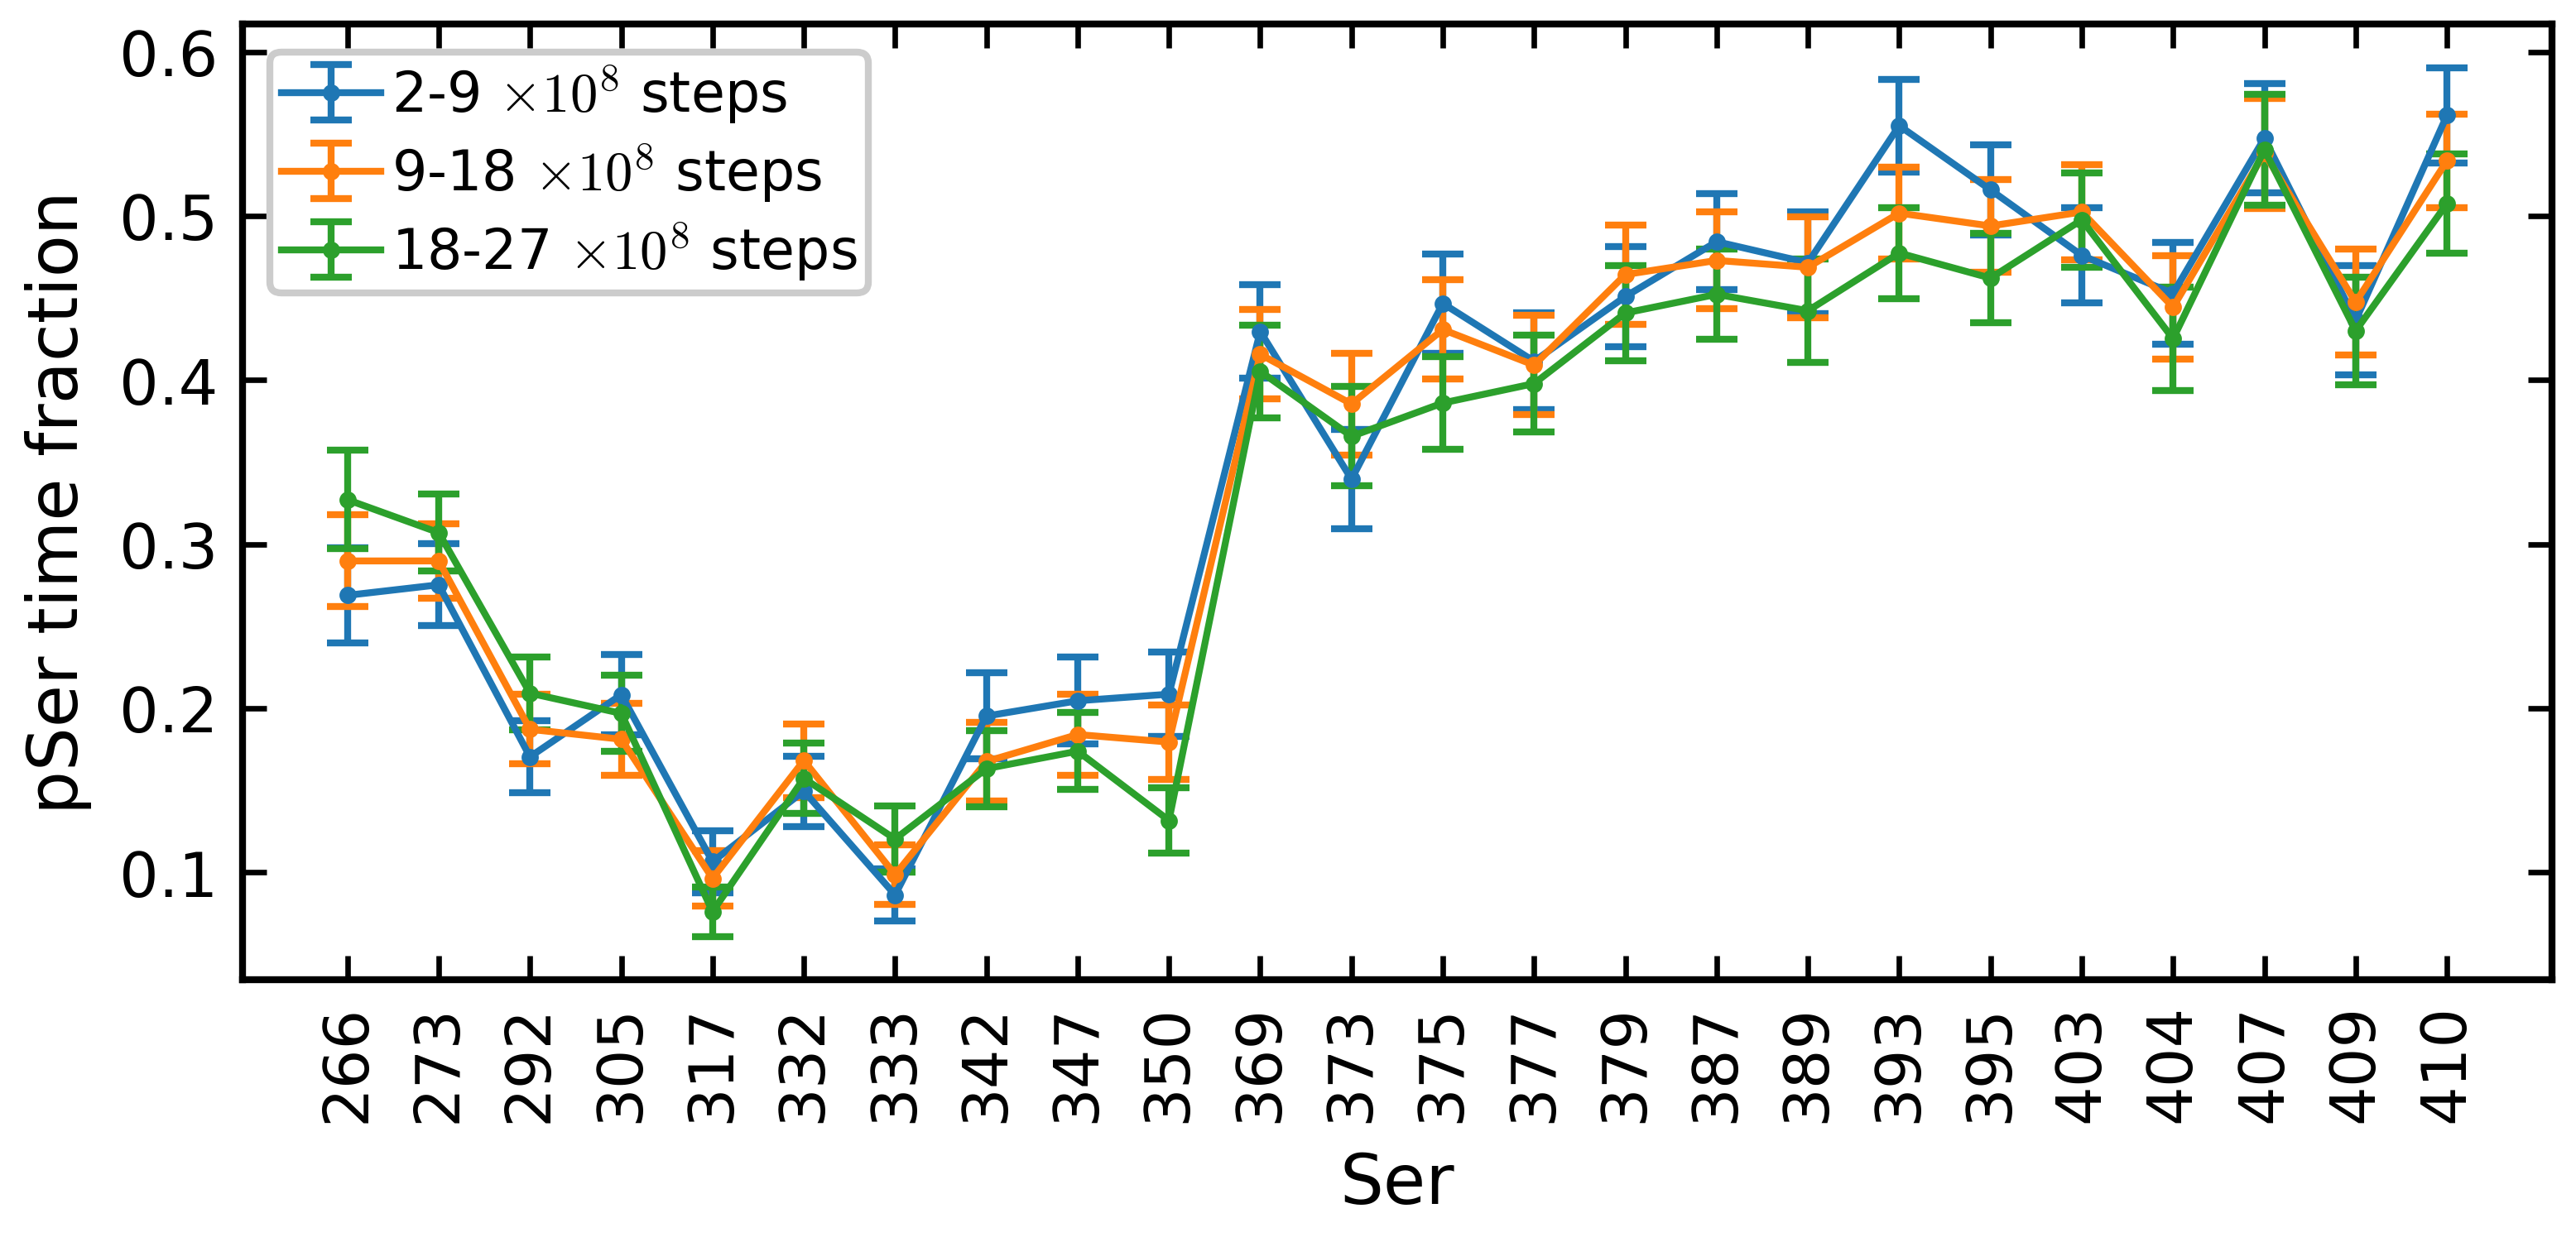

In [29]:
prefix = path_drop_fr + 'sim_ness_200-tdp43-lcd_2-ck1d-open_10-pp3_fr01/sim3_ness_200-tdp43-lcd_2-com-ck1d-open_10-com-pp3_CAL3'
windows = [(2e8, 9e8), (9e8, 18e8), (18e8, 27e8)]

# the _20us contacts file contains all the reactions from t = 0; fractions of the serines, shape (windows, chains, serines)
frac_10 = cached(rates_dir + 'phospho_time_fraction_200-tdp43-lcd_2-ck1d-open_10-pp3_sim1.npz', lambda: dict(
    fractions=np.array([phosphorylation_fraction_per_residue(prefix + '_fr01_start.gsd', prefix + '_fr01_20us_contacts.txt',
                                                             N_CHAINS, CHAIN_LENGTH, t_end, t_therm=t_therm)[:, SER_I]
                        for t_therm, t_end in windows]), windows=np.array(windows)))['fractions']

plot_fractions(frac_10, [rf'{t0 / 1e8:.0f}-{t1 / 1e8:.0f} $\times 10^8$ steps' for t0, t1 in windows],
               path_drop_fr_pl + 'sim_ness_200-tdp43-lcd_2-ck1d-open_10-pp3_fr01/phosho_time_fraction_200-tdp43-lcd_2-ck1d-open_10-pp3_fr01')

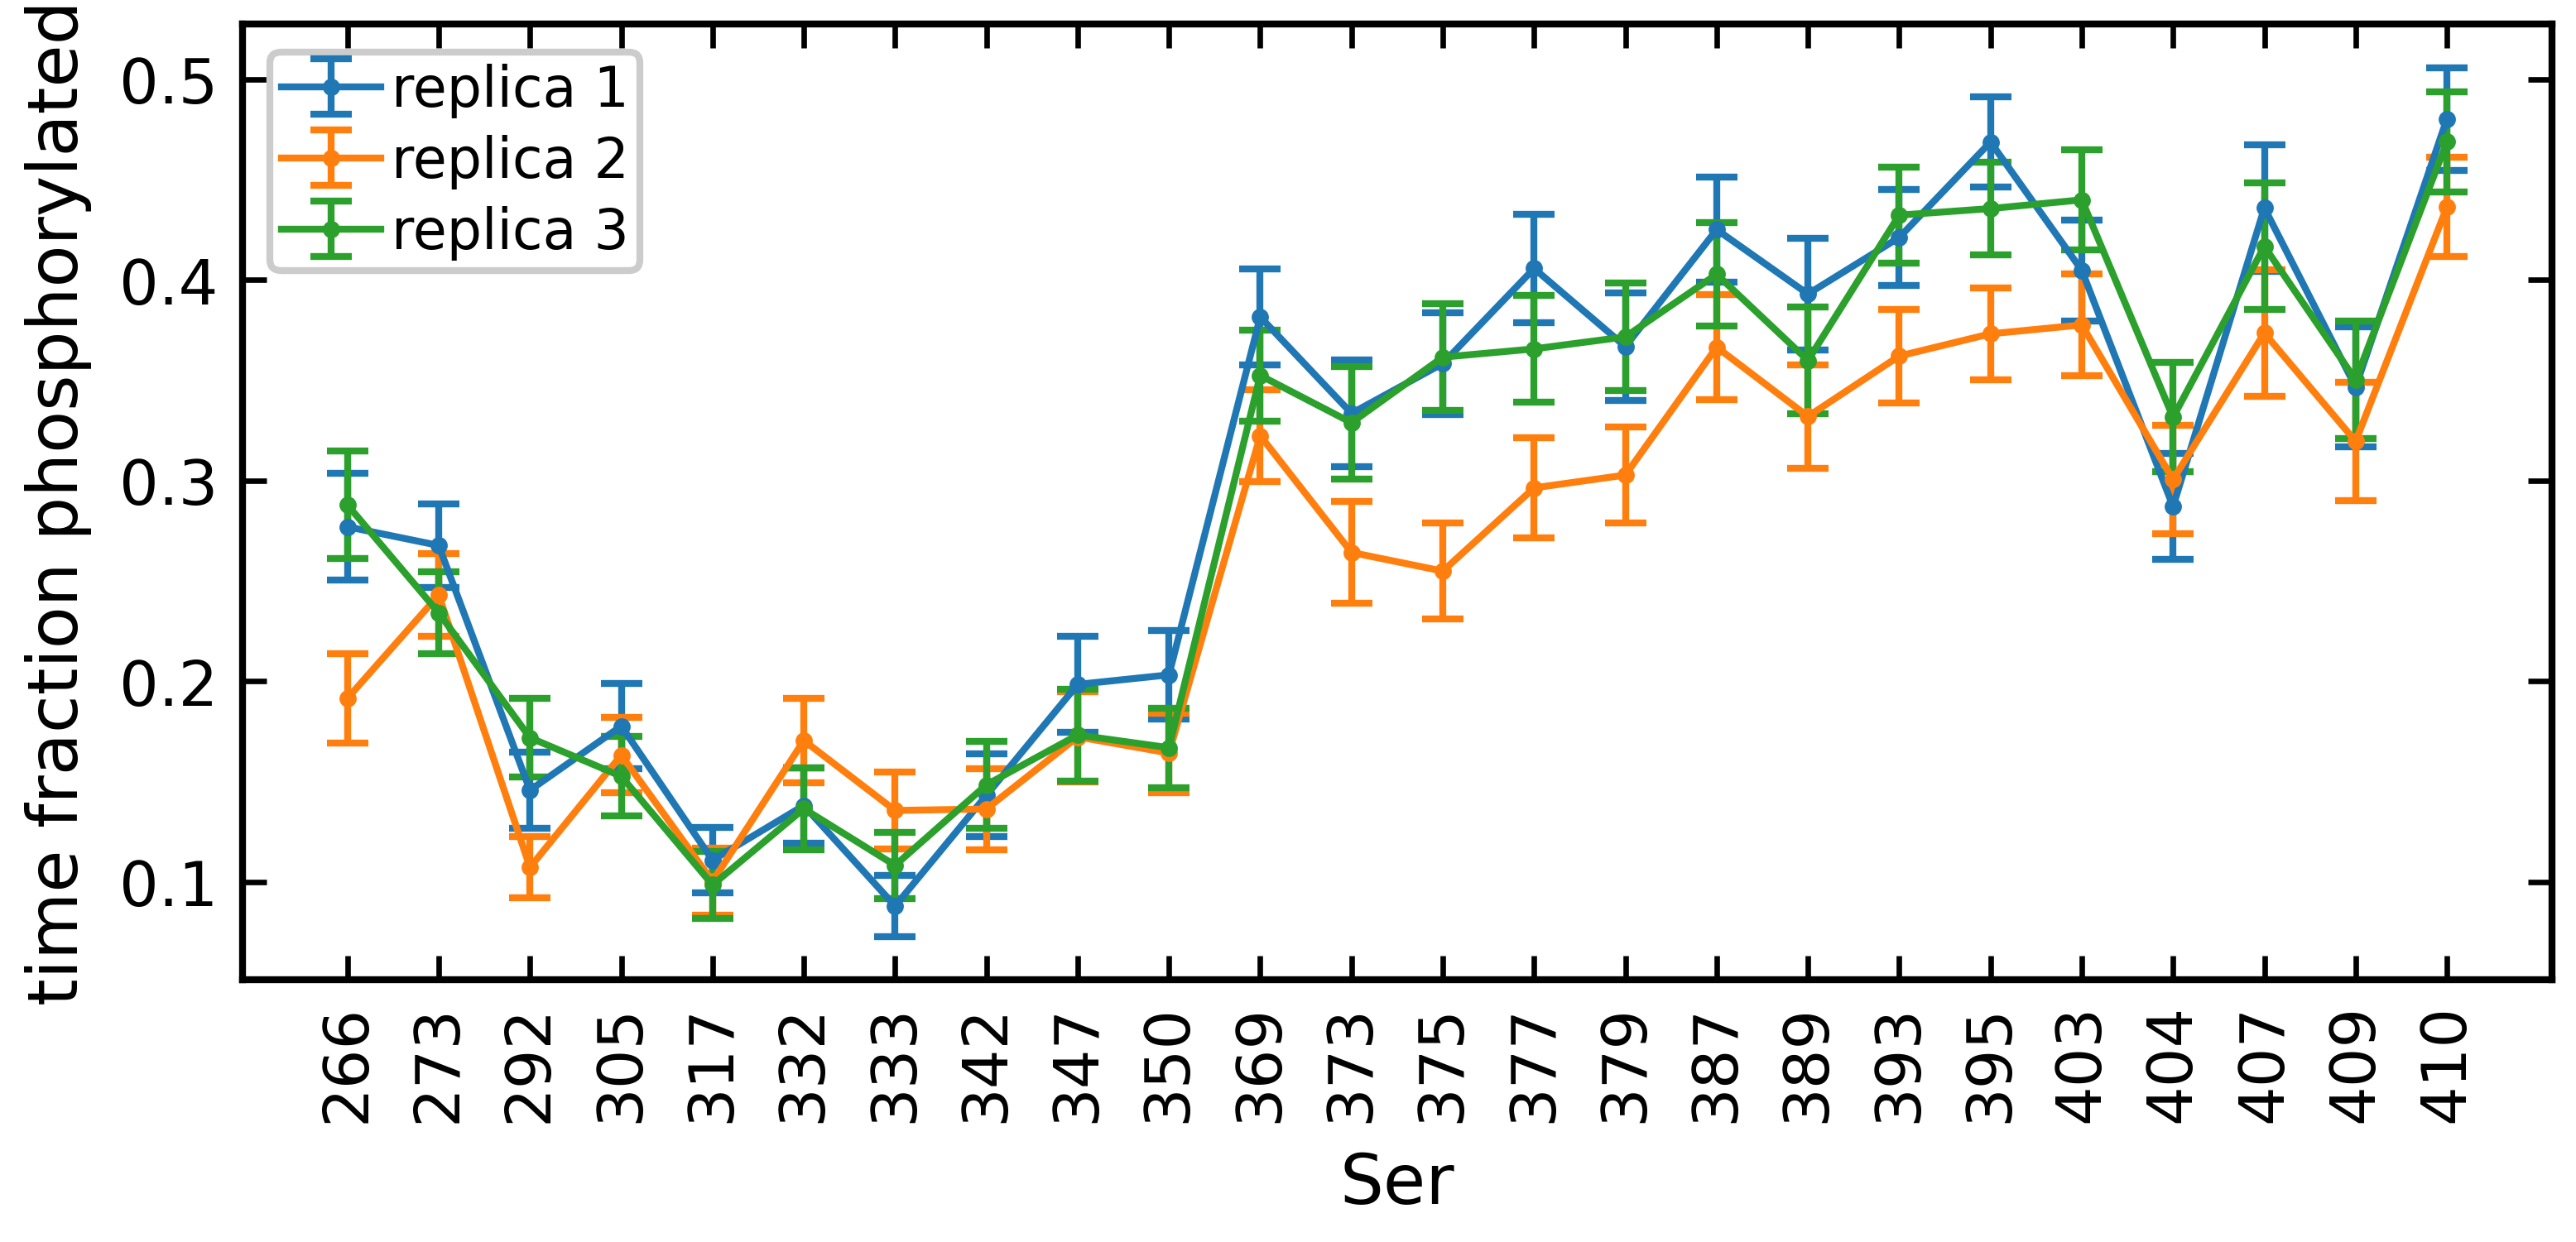

In [7]:
dir_pt = path_drop_fr + 'sim_ness_200-tdp43-lcd_2-ck1d-open_16-pp3_fr01/'
suffix = 'ness_200-tdp43-lcd_2-com-ck1d-open_16-com-pp3_CAL3'
t_therm, t_end = 10e8, 19.9e8

# fractions of the serines of every replica, shape (replicas, chains, serines)
frac_16 = cached(rates_dir + 'phospho_time_fraction_200-tdp43-lcd_2-ck1d-open_16-pp3_sims123.npz', lambda: dict(
    fractions=np.array([phosphorylation_fraction_per_residue(dir_pt + f'sim{ss}_{suffix}_fr01_start.gsd',
                                                             dir_pt + f'sim{ss}_{suffix}_fr01_contacts.txt',
                                                             N_CHAINS, CHAIN_LENGTH, t_end, t_therm=t_therm)[:, SER_I]
                        for ss in (1, 2, 3)]), window=np.array([t_therm, t_end])))['fractions']

plot_fractions(frac_16, [f'replica {ss}' for ss in (1, 2, 3)],
               path_drop_fr_pl + 'sim_ness_200-tdp43-lcd_2-ck1d-open_16-pp3_fr01/phosho_time_fraction_200-tdp43-lcd_2-ck1d-open_16-pp3_fr01')

# 3. pSer in time with a single kind of enzyme
200 LCD chains with 5 CK1δ (phosphorylation, 10 µs) or 5 PP3 (dephosphorylation, 20 µs); averages over 4 replicas.
Cluster sizes: chains in the largest cluster (centered dumps), averaged over the replicas.
pSer bands: standard error of the replica means. Time series saved in `rates_dir`, fitted rates in `fitted_rates.txt`.

In [3]:
step = 20
times_20us = np.arange(step, 10000 + step, step) - 1    # dump frames
times_10us = np.arange(step, 5000 + step, step) - 1
time_0_20us = times_20us * DT_SNAP / 1e8
time_0_10us = times_10us * DT_SNAP / 1e8



def single_enzyme_series(folder, name, times):
    '''Total pSer (mean over 4 replicas, standard error of the replica means) and chains in the largest cluster.'''
    def compute():
        pser, d_pser = hpar.pSer_per_chain(dirpath=path_drop_fr + folder, file_suffix=f'{name}_fr01_dump.gsd', n_sims=4,
                                           times=times, len_prot=CHAIN_LENGTH, n_prot=N_CHAINS, error='replicas')
        nc, _ = hpacl.chains_in_condensate(path_drop_fr + folder, f'{name}_fr01_dump_centered.gsd', 4, times)
        return dict(times=times, pser=pser * N_CHAINS, d_pser=d_pser * N_CHAINS, n_cond=nc[:, 0])
    return cached(rates_dir + f'pser_and_cluster_in_time_{name}.npz', compute)


s_dp = single_enzyme_series('sim_200-tdp43-lcd_5-pp3_dmu8_fr01/', '200-tdp43-lcd_5-com-pp3_CAL3', times_20us)
s_p = single_enzyme_series('sim_200-tdp43-lcd_5-ck1d-open_fr01/', '200-tdp43-lcd_5-com-ck1d-open_CAL3', times_10us)
pSer_cond_dp, d_pSer_cond_dp, nc_5pp3 = s_dp['pser'], s_dp['d_pser'], s_dp['n_cond']
pSer_cond_p, d_pSer_cond_p, nc_5ck1d = s_p['pser'], s_p['d_pser'], s_p['n_cond']

In [4]:
# kinase: linear growth while the droplet is condensed and after it dissolves
popt_p1, pcov_p1 = curve_fit(linear, time_0_10us[10:55], pSer_cond_p[10:55])
popt_p2, pcov_p2 = curve_fit(linear, time_0_10us[115:225], pSer_cond_p[115:225])
print('kinase, condensed: slope', popt_p1[0], '+-', np.sqrt(pcov_p1[0, 0]))

# kinase: exponential approach to full phosphorylation (4800 serines)
popt_exp_p, pcov_exp_p = curve_fit(linear, time_0_10us[30:55], np.log(4800 - pSer_cond_p[30:55]))
print('kinase, exponential:', popt_exp_p, np.sqrt(pcov_exp_p.diagonal()))

# phosphatase: exponential decay
popt_exp, pcov_exp = curve_fit(linear, time_0_20us, np.log(pSer_cond_dp))
print('phosphatase, exponential:', popt_exp, np.sqrt(pcov_exp.diagonal()))

with open(rates_dir + 'fitted_rates.txt', 'w') as fh:
    fh.write('# fit value error   (time in 1e8 MD steps = us)\n')
    for name, popt, pcov in [('kinase_condensed_slope [pSer/us]', popt_p1, pcov_p1),
                             ('kinase_dissolved_slope [pSer/us]', popt_p2, pcov_p2),
                             ('kinase_exponential_rate (4800 - N_pSer) [1/us]', popt_exp_p, pcov_exp_p),
                             ('phosphatase_exponential_rate [1/us]', popt_exp, pcov_exp)]:
        fh.write(f'{name} {popt[0]:.6g} {np.sqrt(pcov[0, 0]):.3g}\n')

kinase, condensed: slope 750.3269098446302 +- 4.574607506766
kinase, exponential: [-0.19288833  8.51955727] [0.0009458  0.00164763]
phosphatase, exponential: [-0.03802023  7.64789275] [4.39248453e-05 5.07885046e-04]


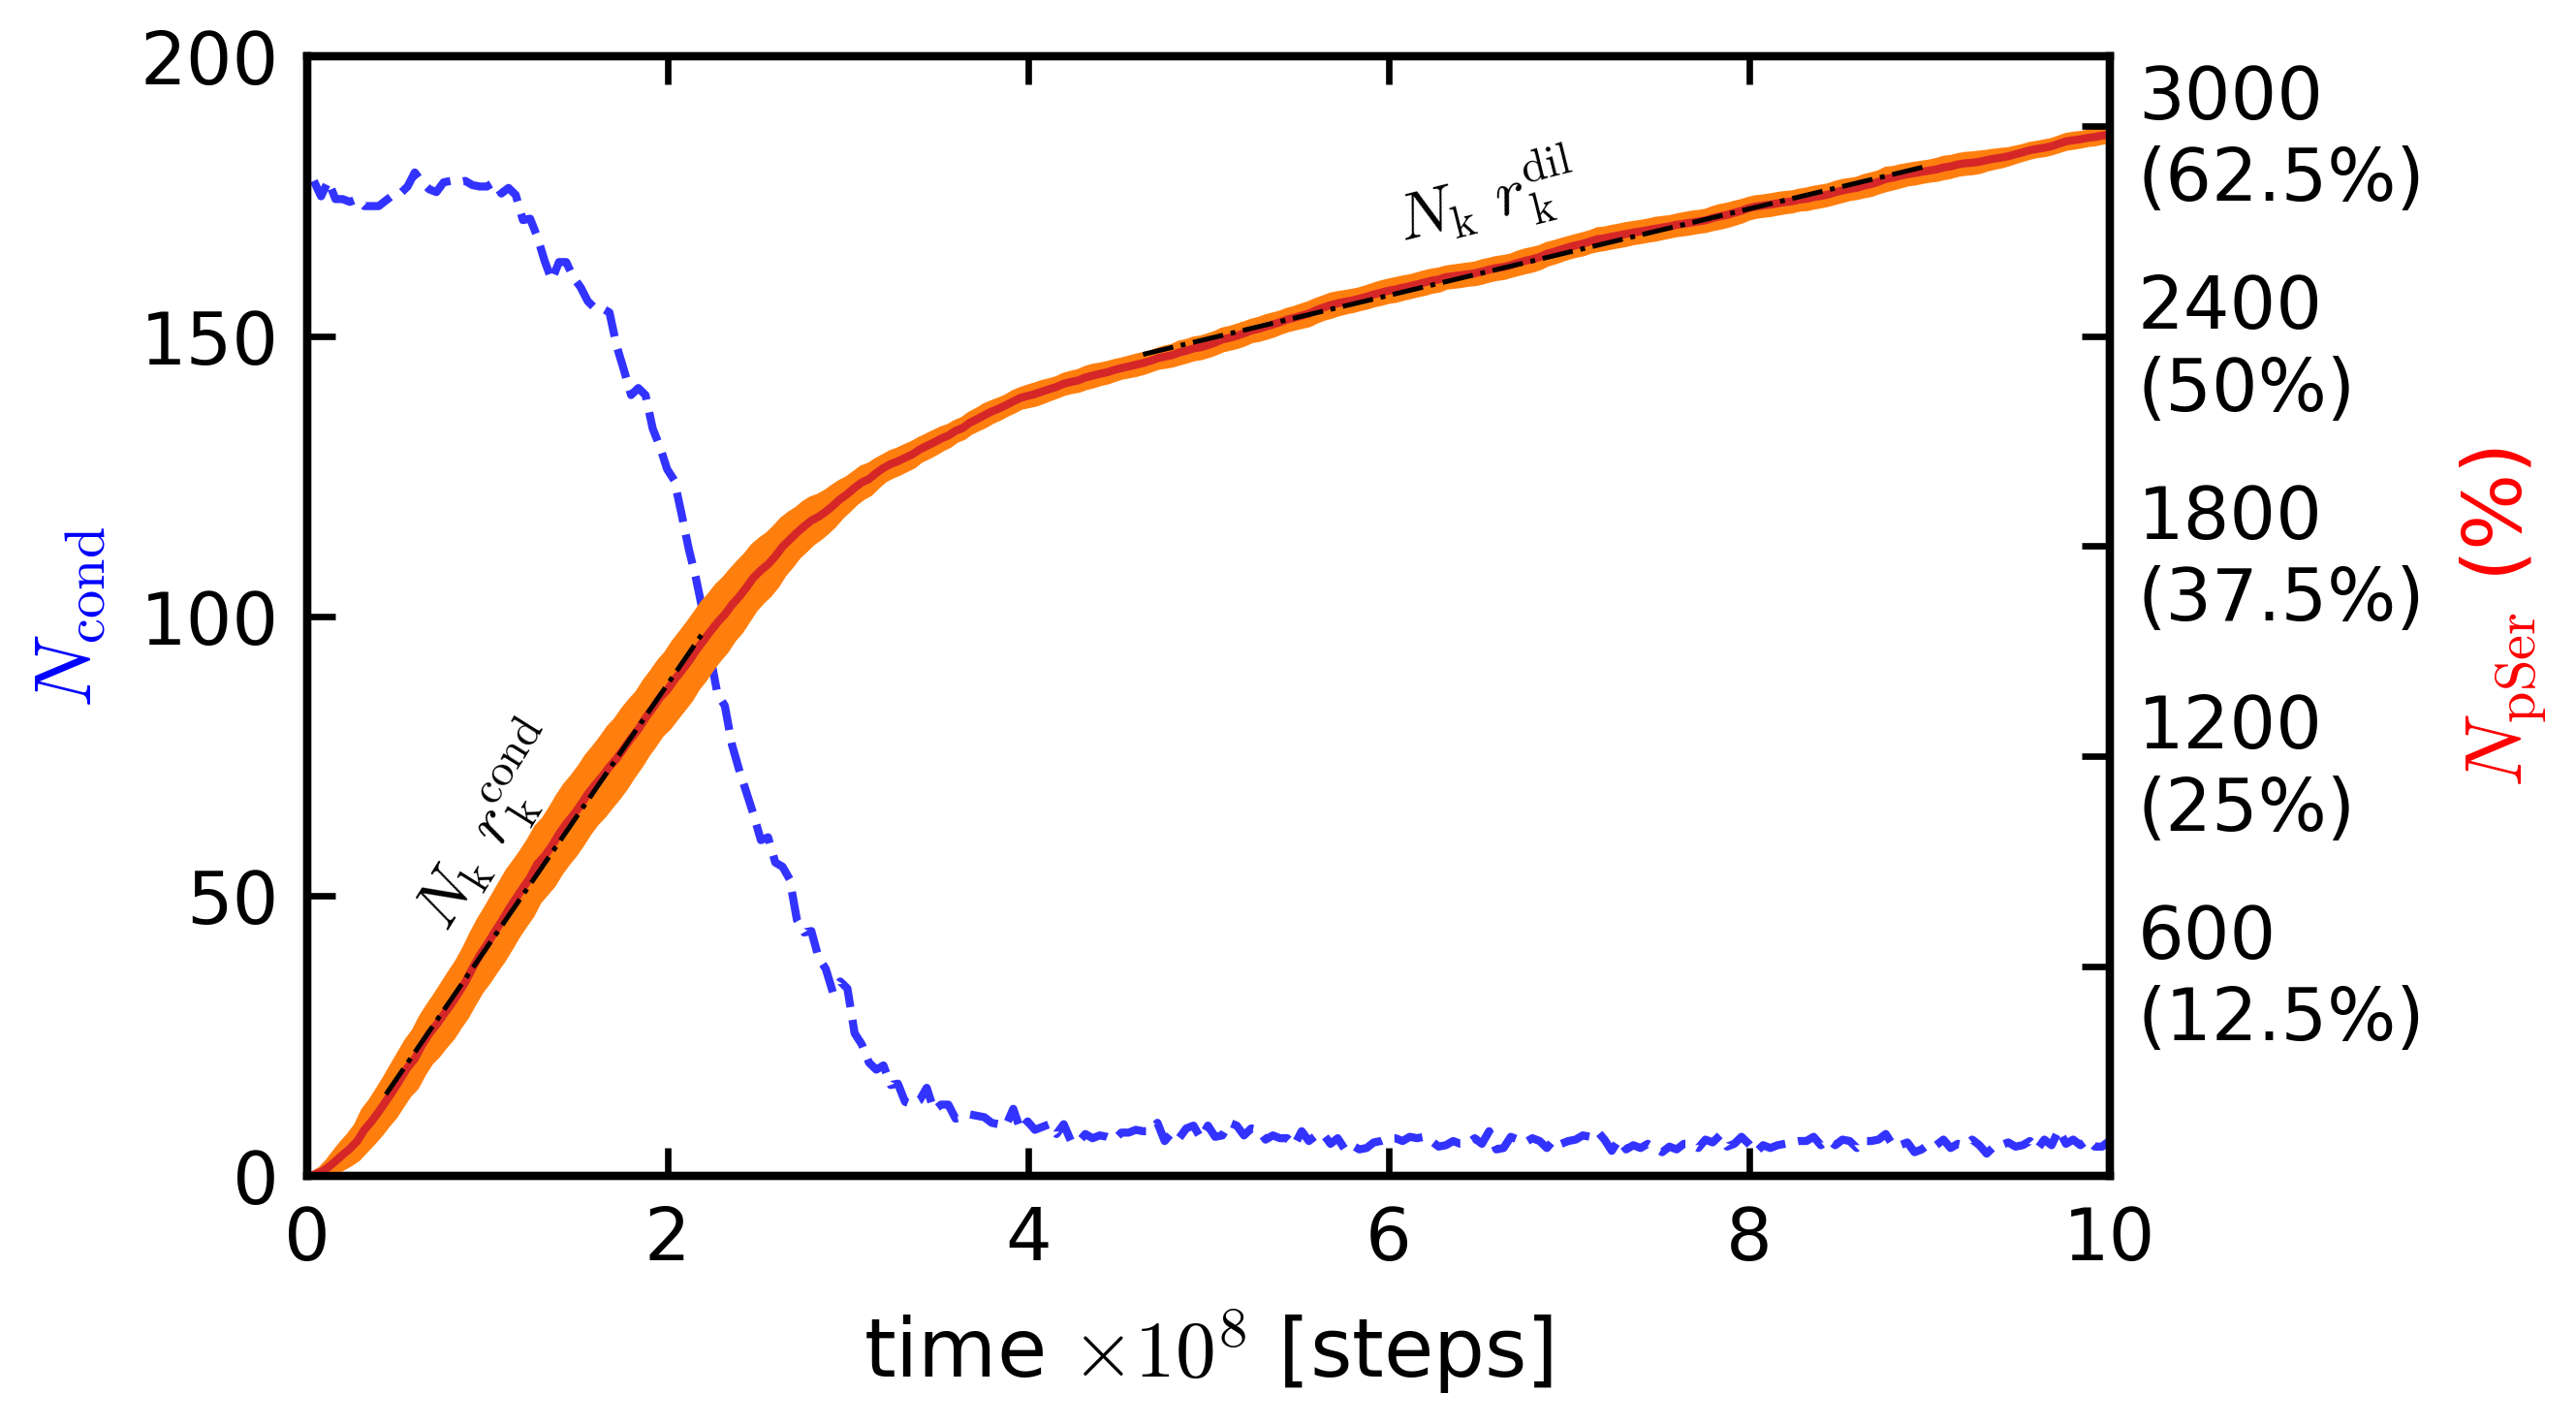

In [5]:
fig, ax1 = plt.subplots(figsize=(4, 2.5))
ax2 = ax1.twinx()
ax2.plot(time_0_10us, pSer_cond_p, 'tab:red', label='5 CK1d')
ax2.fill_between(time_0_10us, pSer_cond_p - d_pSer_cond_p, pSer_cond_p + d_pSer_cond_p, color='tab:orange')
ax2.plot(time_0_10us[10:55], linear(time_0_10us[10:55], *popt_p1), '-.k', lw=0.6)
ax2.plot(time_0_10us[115:225], linear(time_0_10us[115:225], *popt_p2), '-.k', lw=0.6)
ax1.plot(time_0_10us, nc_5ck1d, '--', color='b', alpha=0.8)

ax1.set_xlabel(r'time $\times 10^8$ [steps]')
ax2.set_ylabel(r'$N_\mathrm{pSer}$ (%)', color='r')
ax1.set_ylabel(r'$N_{\mathrm{cond}}$', color='b')
ax2.set_ylim(0, 16. * 200)
ax1.set_ylim(0, 200)
ax1.set_xlim(0., 10)
ax1.text(.5, 45, r'$N_\mathrm{k}$ $r\mathrm{_k^{cond}}$', rotation=58, fontsize=8)
ax1.text(6., 167, r'$N_\mathrm{k}$ $r\mathrm{_k^{dil}}$', rotation=14, fontsize=8)
ax2.set_yticks([600, 1200, 1800, 2400, 3000], ['600\n(12.5%)', '1200\n(25%)', '1800\n(37.5%)', '2400\n(50%)', '3000\n(62.5%)'])
savefig(path_drop_fr_pl + 'sim_200-tdp43-lcd_5-ck1d-open_fr01/n_pser_in_time_200-tdp43-lcd_5-ck1d-open_v2')

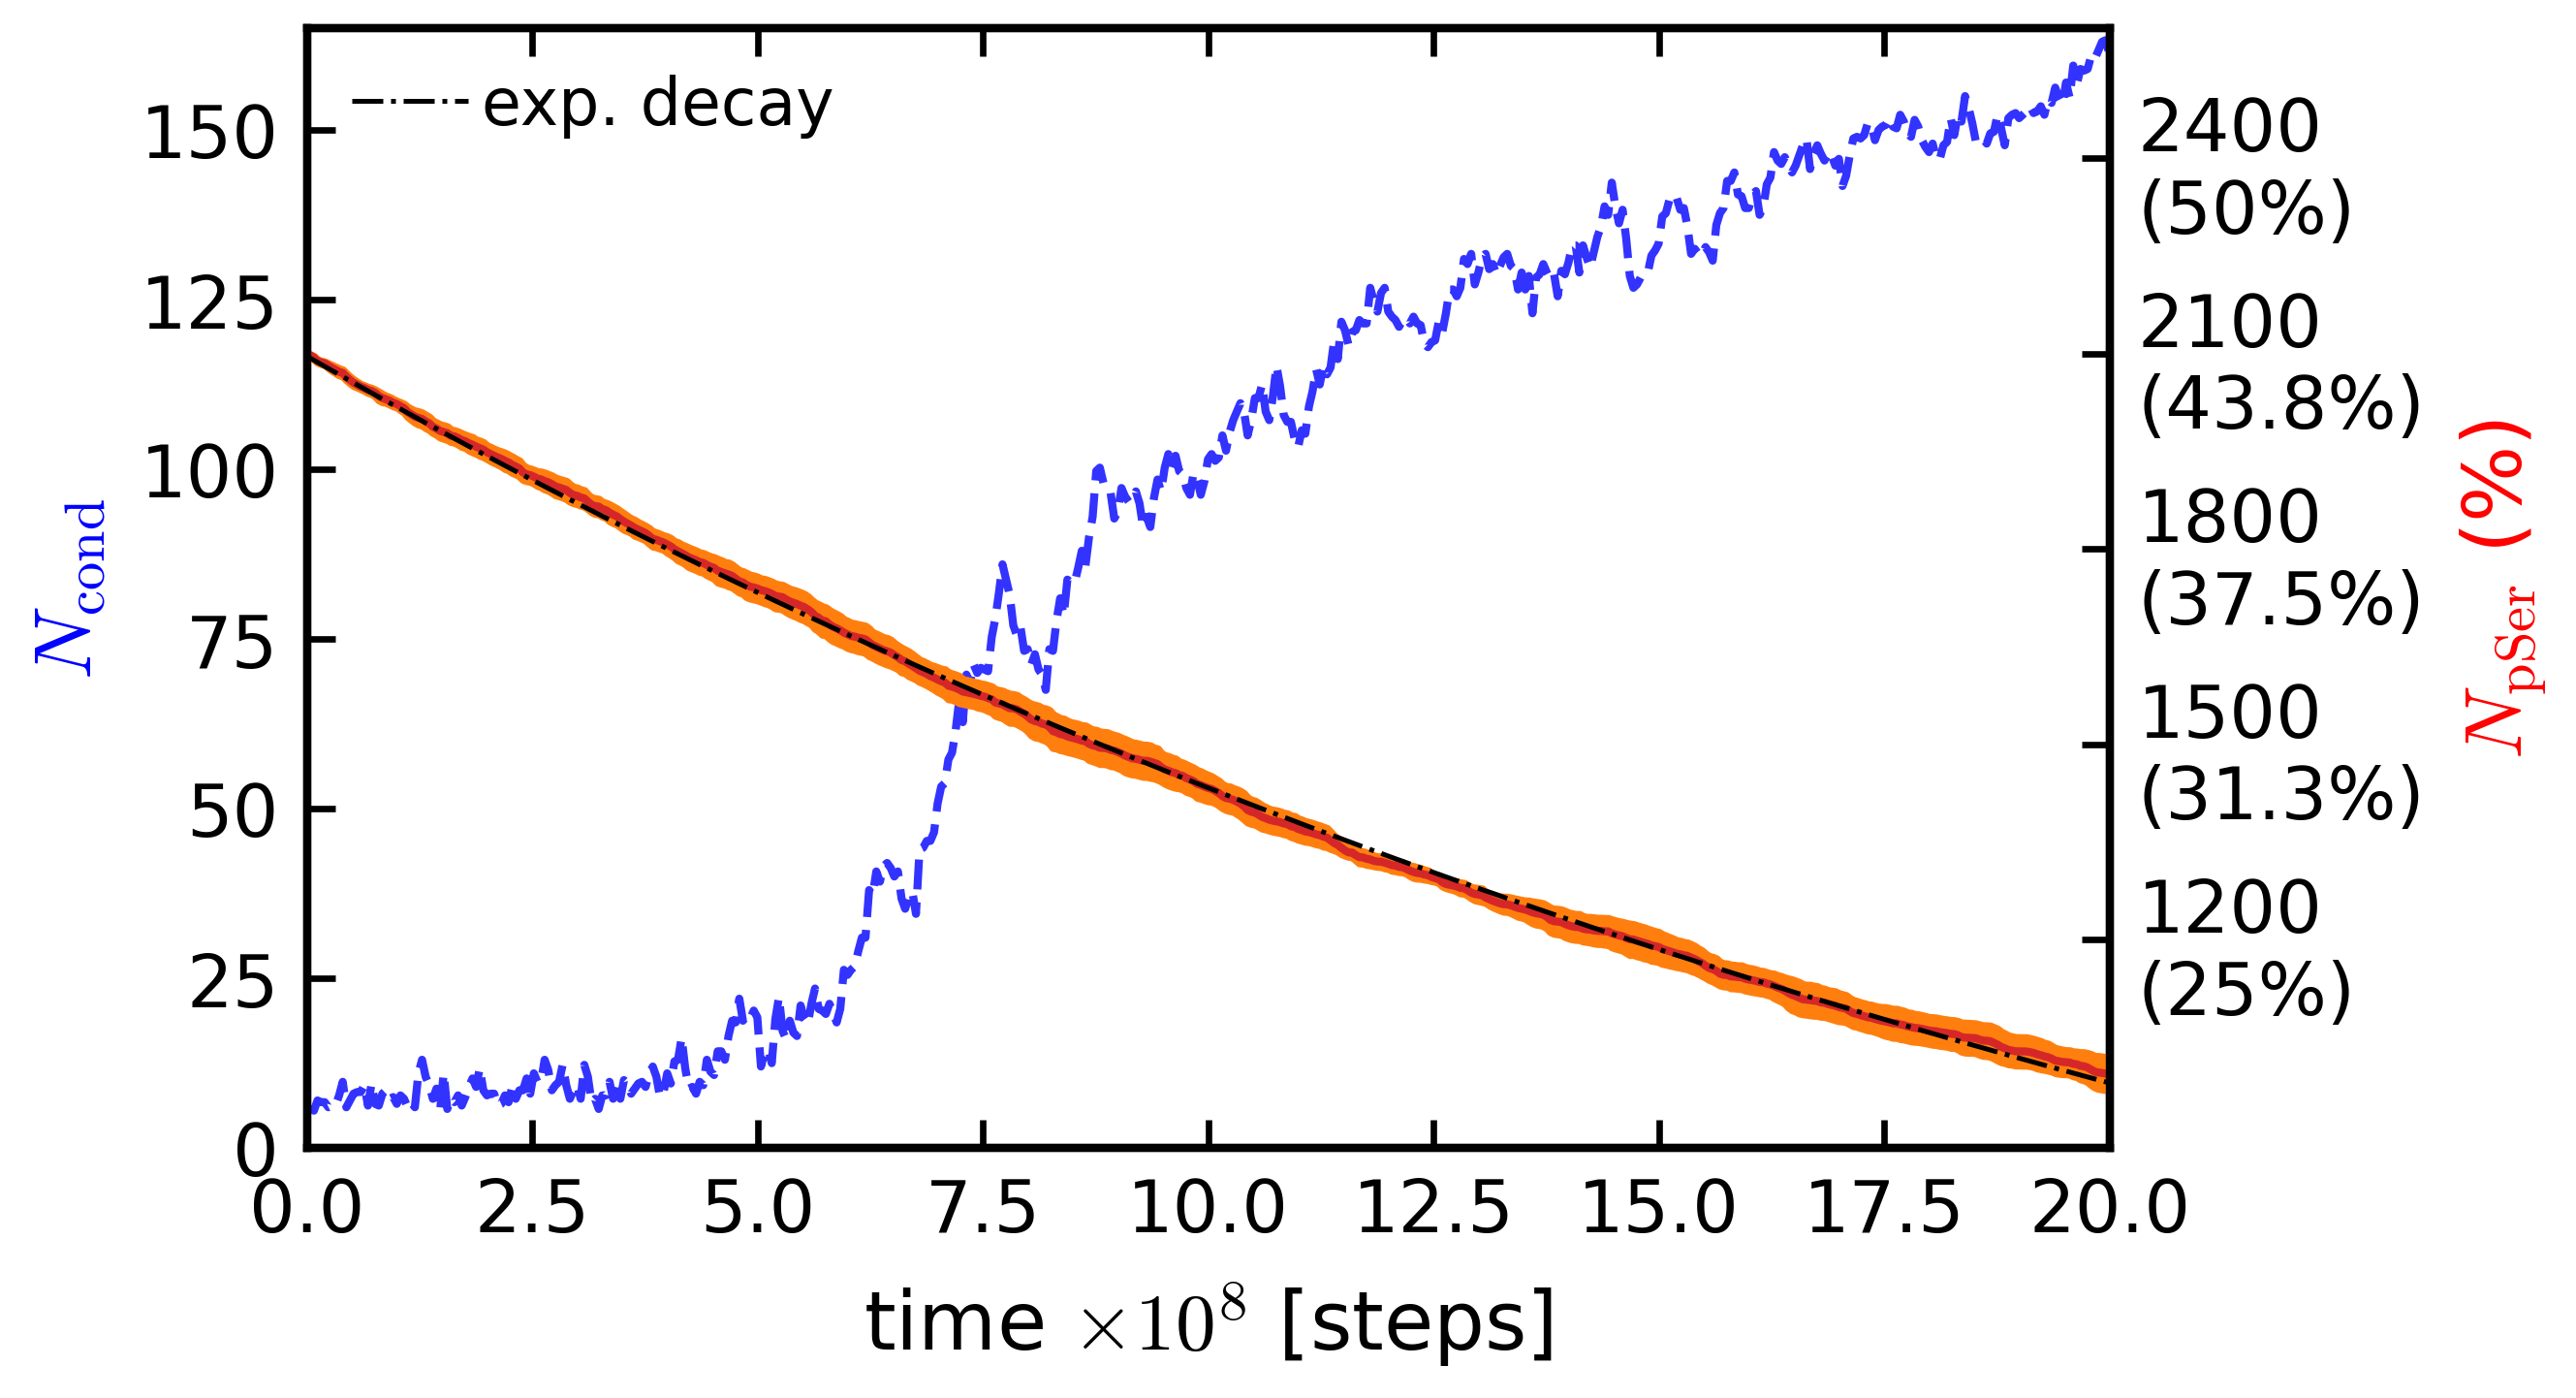

In [6]:
fig, ax1 = plt.subplots(figsize=(4, 2.5))
ax2 = ax1.twinx()
ax2.plot(time_0_20us, pSer_cond_dp, 'tab:red')
ax2.fill_between(time_0_20us, pSer_cond_dp - d_pSer_cond_dp, pSer_cond_dp + d_pSer_cond_dp, color='tab:orange')
ax2.plot(time_0_20us, np.exp(linear(time_0_20us, *popt_exp)), '-.k', lw=0.6, label='exp. decay')
ax1.plot(time_0_20us, nc_5pp3, '--', color='b', alpha=0.8)

ax1.set_xlabel(r'time $\times 10^8$ [steps]')
ax2.set_ylabel(r'$N_\mathrm{pSer}$ (%)', color='r')
ax1.set_ylabel(r'$N_{\mathrm{cond}}$', color='b')
ax2.set_ylim(4.4 * 200, 13. * 200)
ax1.set_ylim(0, 165)
ax1.set_xlim(0., 20)
ax2.legend(ncols=2, loc='upper left', framealpha=0)
ax2.set_yticks([1200, 1500, 1800, 2100, 2400], ['1200\n(25%)', '1500\n(31.3%)', '1800\n(37.5%)', '2100\n(43.8%)', '2400\n(50%)'])
savefig(path_drop_fr_pl + 'sim_200-tdp43-lcd_5-pp3_dmu8_fr01/n_pser_in_time_200-tdp43-lcd_5-pp3_20us_v2')

## Rate vs number of pSer
Local slope of N_pSer(t) from a sliding linear fit over 21 points.

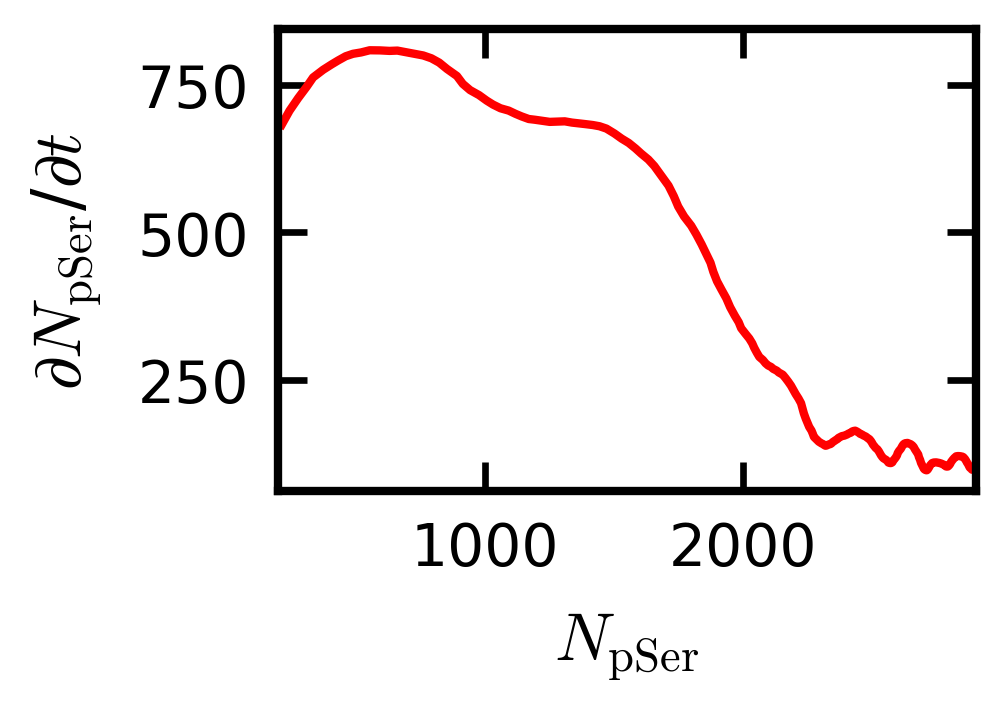

In [12]:
def sliding_poly_rate(t, N, window=21, degree=2, step=1):
    '''Derivative dN/dt at every point from a polynomial fit in a centred window (nan at the edges).'''
    rate = np.full(len(N), np.nan)
    half = window // 2
    for i in range(half, len(N) - half, step):
        indices = np.arange(i - half, i + half + 1, step)
        coeff = np.polyfit(t[indices] - t[i], N[indices], degree)
        rate[i] = np.polyval(np.polyder(coeff), 0)
    return rate


fig, ax1 = plt.subplots(figsize=(1.5, 1.))
plt.plot(pSer_cond_p, sliding_poly_rate(time_0_10us, pSer_cond_p, 21, 1), c='r')
ax1.set_xlabel(r'$N_\mathrm{pSer}$', fontsize=8)
ax1.set_ylabel(r'$\partial N_\mathrm{pSer}$/$\partial t$', fontsize=8)
ax1.set_xlim(200., 14.5 * 200)
ax1.tick_params(labelsize=7)
savefig(path_drop_fr_pl + 'sim_200-tdp43-lcd_5-ck1d-open_fr01/dn_pser_dNp_200-tdp43-lcd_5-ck1d-open')

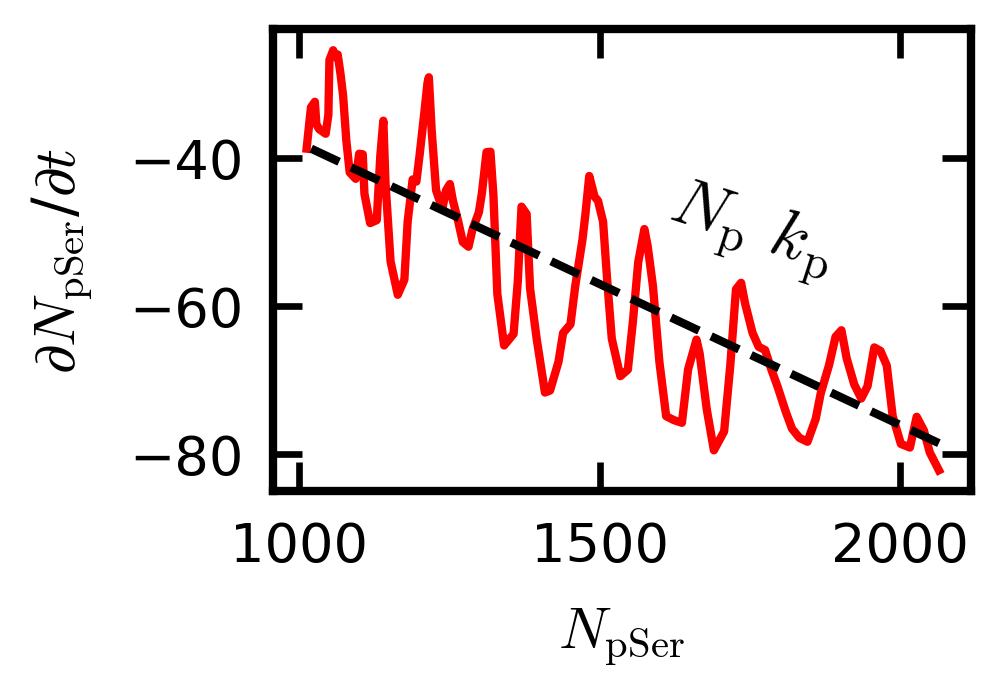

In [13]:
rate_dp = sliding_poly_rate(time_0_20us, pSer_cond_dp, 21, 1)
ok = np.isfinite(rate_dp)
x, y = pSer_cond_dp[ok], rate_dp[ok]

fig, ax1 = plt.subplots(figsize=(1.5, 1.))
plt.plot(x[::4], y[::4], c='r')
plt.plot(x, popt_exp[0] * x, '--k')     # exponential decay: dN/dt = -N_p k_p N
ax1.set_xlabel(r'$N_\mathrm{pSer}$', fontsize=7)
ax1.set_ylabel(r'$\partial N_\mathrm{pSer}$/$\partial t$', fontsize=7)
ax1.tick_params(labelsize=6.5)
ax1.text(1600, -55, r'$N_\mathrm{p}$ $k\mathrm{_p}$', rotation=-18, fontsize=8)
savefig(path_drop_fr_pl + 'sim_200-tdp43-lcd_5-pp3_dmu8_fr01/dn_pser_dNp_200-tdp43-lcd_5-pp3_20us')